Dataset Loaded & Cleaned. Rows: 93487


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


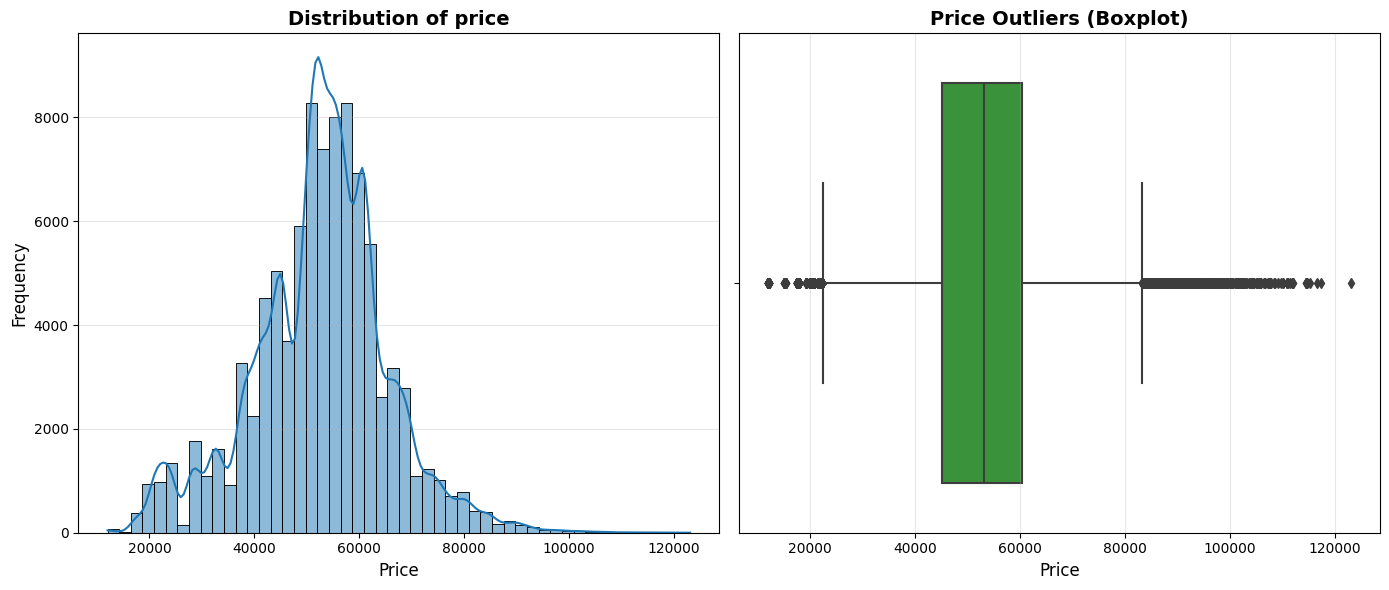

Min Price: 12000
Max Price: 123071
Avg Price: 52540.08
Features used (10): ['date', 'airline', 'ch_code', 'num_code', 'dep_time', 'from', 'time_taken', 'stop', 'arr_time', 'to']
Training samples:   59832
Validation samples: 14957
Testing samples:    18698


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │       103,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,665 (444.00 KB)

 Trainable params: 113,665 (444.00 KB)

 Non-trainable params: 0 (0.00 B)


--- Starting Training ---
Epoch 1/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 1032617472.0000 - mean_absolute_error: 23176.7266 - val_loss: 44253712.0000 - val_mean_absolute_error: 4620.6782
Epoch 2/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 53824680.0000 - mean_absolute_error: 5381.2344 - val_loss: 39313092.0000 - val_mean_absolute_error: 4320.9985
Epoch 3/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 50579392.0000 - mean_absolute_error: 5232.7969 - val_loss: 37678604.0000 - val_mean_absolute_error: 4248.7598
Epoch 4/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 49457048.0000 - mean_absolute_error: 5146.5840 - val_loss: 36768332.0000 - val_mean_absolute_error: 4151.0225
Epoch 5/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 48578852.0000 - mean_absolute_error: 5081.8374 - val_loss: 35671596.0000 - val_mean_absolute_error: 4071.8508
Epoch 6/50
1870/1870 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 47210176.0000 - mean_absolute_error: 5003.4551 

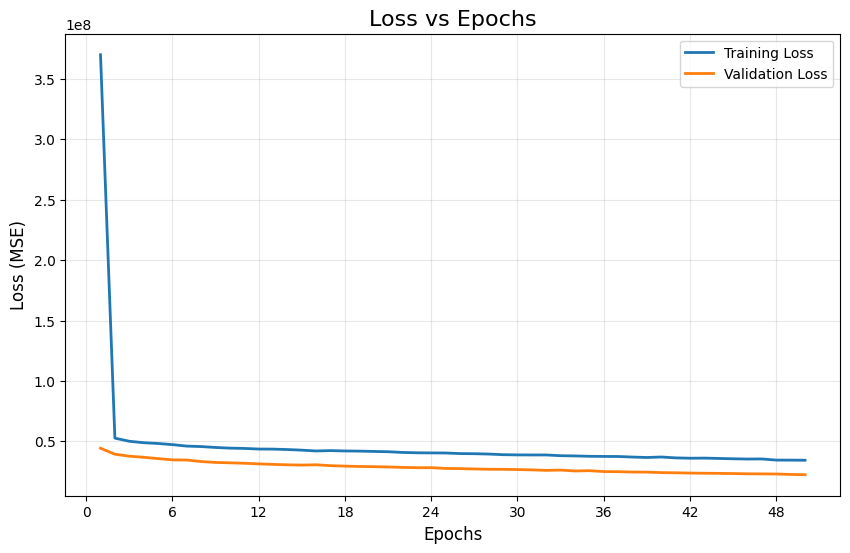

2338/2338 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
585/585 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

FINAL RESULTS
Training MAPE: 5.30%
Testing MAPE:  5.41%
R² Score:      0.8699
--------------------------------------------------
Interpretation: On average, prediction error is 5.41%.


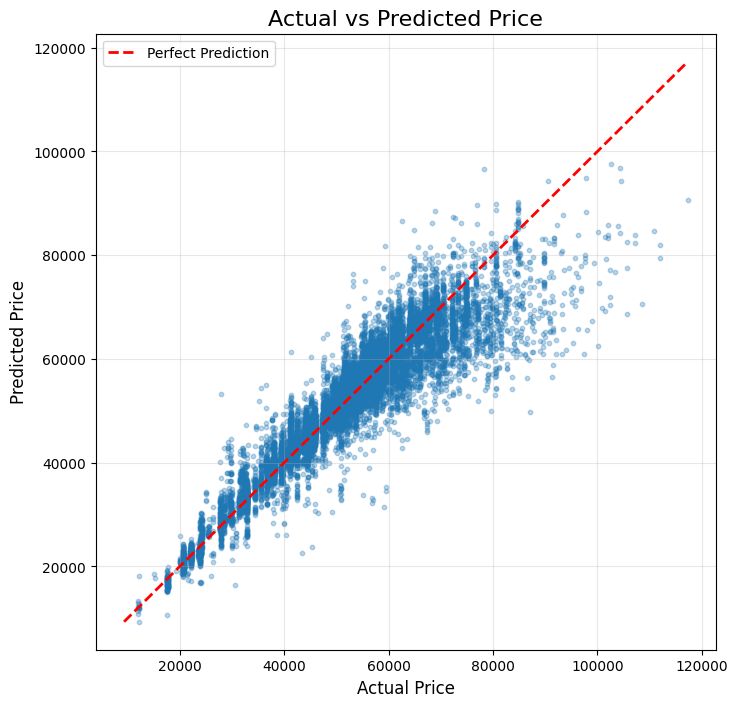

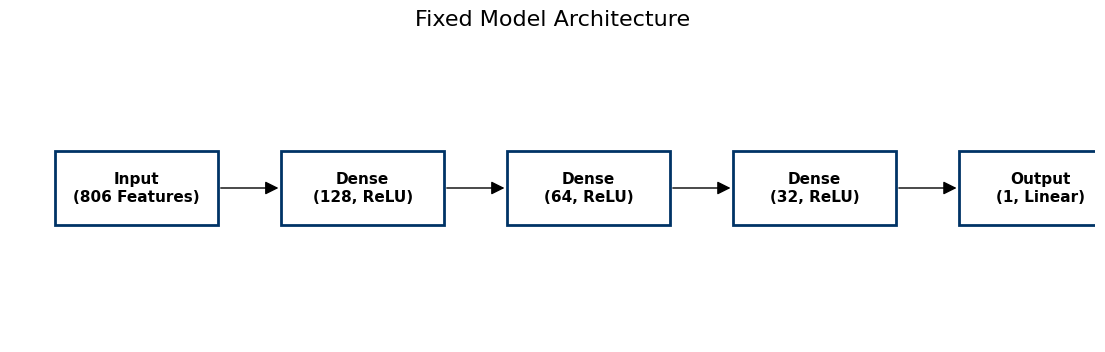

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from matplotlib.ticker import MaxNLocator

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

#data
dataset_path = "/kaggle/input/flight-price-prediction"
files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]
df = pd.read_csv(os.path.join(dataset_path, files[0]))

#drop index column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')


#we must convert Price to numbers BEFORE plotting
target_col = 'price'

# Remove commas "5,999" -> 5999
if df[target_col].dtype == 'object':
    df[target_col] = df[target_col].astype(str).str.replace(',', '')
    df[target_col] = pd.to_numeric(df[target_col], errors='coerce')

# Remove NaNs
df = df.dropna(subset=[target_col])

print(f"Dataset Loaded & Cleaned. Rows: {len(df)}")

#visualisation initial price data
plt.figure(figsize=(14, 6))

#histogram, distribution
plt.subplot(1, 2, 1)
sns.histplot(df[target_col], kde=True, color='#1f77b4', bins=50)
plt.title(f"Distribution of {target_col}", fontsize=14, fontweight='bold')
plt.xlabel("Price", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis='y', alpha=0.3)

#boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df[target_col], color='#2ca02c')
plt.title(f"Price Outliers (Boxplot)", fontsize=14, fontweight='bold')
plt.xlabel("Price", fontsize=12)
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Print Stats
print(f"Min Price: {df[target_col].min()}")
print(f"Max Price: {df[target_col].max()}")
print(f"Avg Price: {df[target_col].mean():.2f}")

#feature engineering
# Clean 'duration' if it exists (convert to numeric if needed)
if 'duration' in df.columns and df['duration'].dtype == 'object':
    pass 

#ordinal Encoding for 'stops'
mapping_stops = {'zero': 0, 'one': 1, 'two_or_more': 2}
if 'stops' in df.columns:
    df['stops'] = df['stops'].map(mapping_stops).fillna(0)

#drop high cardinality columns
cols_to_drop = ['flight', 'duration'] # Dropping duration to prevent string errors
X = df.drop(columns=cols_to_drop + [target_col], errors='ignore')
y = df[target_col]

print(f"Features used ({len(X.columns)}): {X.columns.tolist()}")

#preprocessing
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

X_processed = preprocessor.fit_transform(X)

if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

#force numeric type to avoid object errors
X_processed = np.asarray(X_processed).astype(np.float32)
y = np.asarray(y).astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

#summary of data split
train_count = len(X_train)
test_count = len(X_test)

# From model.fit (validation_split=0.2) -> validation = 20% of training data
val_count = int(train_count * 0.2)
actual_train_count = train_count - val_count

print(f"Training samples:   {actual_train_count}")
print(f"Validation samples: {val_count}")
print(f"Testing samples:    {test_count}")


#architecture of the network
model = keras.Sequential([
    layers.InputLayer(input_shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='linear') 
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error', 
    metrics=['mean_absolute_error']
)

model.summary()

#training
stop_early = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

print("\n--- Starting Training ---")
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[stop_early],
    verbose=1
)

#loss curve
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, train_loss, label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', linewidth=2)
plt.title('Loss vs Epochs', fontsize=16)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
ax = plt.gca()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

#metrics and MAPE
y_train_pred = model.predict(X_train).flatten()
y_test_pred = model.predict(X_test).flatten()

def calculate_mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true > 0
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

train_mape = calculate_mape(y_train, y_train_pred)
test_mape = calculate_mape(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
r2 = r2_score(y_test, y_test_pred)

print("\n" + "="*50)
print("FINAL RESULTS")
print("="*50)
print(f"Training MAPE: {train_mape:.2f}%")
print(f"Testing MAPE:  {test_mape:.2f}%")
print(f"R² Score:      {r2:.4f}")
print("-" * 50)
print(f"Interpretation: On average, prediction error is {test_mape:.2f}%.")
print("="*50)

#scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_test_pred, alpha=0.3, color='#1f77b4', s=10)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.title('Actual vs Predicted Price', fontsize=16)
plt.xlabel('Actual Price', fontsize=12)
plt.ylabel('Predicted Price', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#Drawing the diagram
def draw_model_architecture(input_shape):
    layer_texts = [
        f"Input\n({input_shape} Features)",
        "Dense\n(128, ReLU)",
        "Dense\n(64, ReLU)",
        "Dense\n(32, ReLU)",
        "Output\n(1, Linear)"
    ]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 50)
    ax.axis('off')
    
    num_layers = len(layer_texts)
    box_width = 18
    box_height = 12
    gap = 7
    start_x = 5
    center_y = 25
    
    for i, text in enumerate(layer_texts):
        x = start_x + i * (box_width + gap)
        y = center_y - (box_height / 2)
        rect = patches.Rectangle((x, y), box_width, box_height, linewidth=2, edgecolor='#003366', facecolor='white')
        ax.add_patch(rect)
        ax.text(x + box_width/2, center_y, text, ha='center', va='center', fontsize=11, color='black', fontweight='bold')
        
        if i < num_layers - 1:
            arrow = patches.FancyArrowPatch(
                (x + box_width, center_y), (x + box_width + gap, center_y),
                mutation_scale=20, color='black', arrowstyle='-|>'
            )
            ax.add_patch(arrow)
    plt.title("Fixed Model Architecture", fontsize=16)
    plt.show()

draw_model_architecture(X_train.shape[1])